# AI4I 2020 Predictive Maintenance - Logistic Regression

## CIS 480 Capstone | Baseline classification model

### Based on logistic regression section of first_vertical_slice.ipynb. Uses the cleaned CSV generated by src/cleaning/clean_ai4i.py.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

# Import shared utilities from src/modeling/, regardless of notebook working directory.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "src" / "modeling" / "model_utils.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Expected src/modeling/model_utils.py under the project root")
sys.path.insert(0, str(PROJECT_ROOT / "src" / "modeling"))
from model_utils import (PREDICTORS, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                         RANDOM_STATE, CV_SCORING, load_clean_data, split_data,
                         make_pipeline, make_cv, evaluate_classifier)
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load and validate cleaned data

This notebook uses that cleaned dataset with all 10,000 observations.

In [2]:
df = load_clean_data(PROJECT_ROOT)

predictors = PREDICTORS
outcome = TARGET
required = predictors + [outcome]
print("Rows:", len(df), "| Columns:", len(df.columns))

display(df[required].head())

display(pd.DataFrame({"count": df[outcome].value_counts().sort_index(),
                      "percent": (df[outcome].value_counts(normalize=True).sort_index()*100).round(2)}))

X = df[predictors].copy()
y = df[outcome].copy()


leakage_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF', TARGET]

leaked = set(X.columns) & set(leakage_cols)

assert not leaked, f"Data leakage detected: {leaked}"


Rows: 10000 | Columns: 14


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


,count,percent
Machine failure,,
0,9661,96.61
1,339,3.39


## 3. Stratified training/test split

Use the same 80/20 split and random_state=42 as the initial notebook so later models can be compared fairly. Do not use the test set to select hyperparameters or thresholds.

In [3]:
X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {len(X_train)} ({y_train.mean():.2%} failures)")
print(f"Test:  {len(X_test)} ({y_test.mean():.2%} failures)")

Train: 8000 (3.39% failures)
Test:  2000 (3.40% failures)


## 4. Preprocessing and baseline model

In [4]:
logistic_model = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
logistic_model.fit(X_train, y_train)
print("Baseline logistic regression fitted.")

Baseline logistic regression fitted.


## 5. Cross-validation on training data

Stratified five-fold validation estimates performance before the held-out test evaluation. PR-AUC here is reported as average precision (AP).

In [5]:
cv = make_cv()
scoring = CV_SCORING
cv_scores = cross_validate(logistic_model, X_train, y_train, cv=cv,
                           scoring=scoring, n_jobs=-1)
cv_summary = pd.DataFrame({k: [cv_scores[f"test_{k}"].mean(), cv_scores[f"test_{k}"].std()]
                           for k in scoring}, index=["Mean", "Std dev"]).T
display(cv_summary.round(4))

,Mean,Std dev
precision,0.7607,0.1089
recall,0.1993,0.0276
f1,0.3119,0.0260
roc_auc,0.8938,0.0168
average_precision,0.4686,0.0319


## 6. Evaluate on the held-out test set

Keep the default 0.50 probability threshold for the baseline.

In [6]:
metrics, y_pred, y_prob = evaluate_classifier(logistic_model, X_test, y_test)
display(metrics.round(4))
print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"], zero_division=0))

,Metric,Score
0,Accuracy,0.9675
1,Precision,0.6364
2,Recall,0.1029
3,F1 Score,0.1772
4,ROC-AUC,0.8994
5,Average Precision (PR-AUC),0.4205


              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



## 7. Performance visualizations

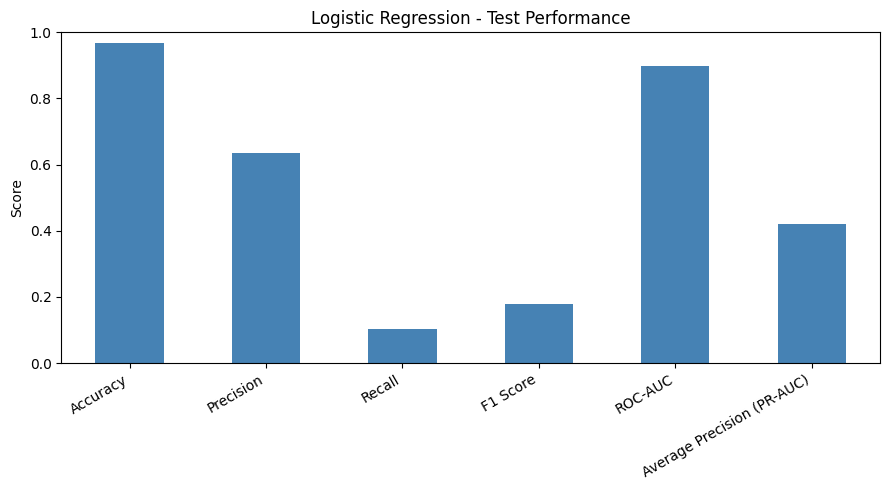

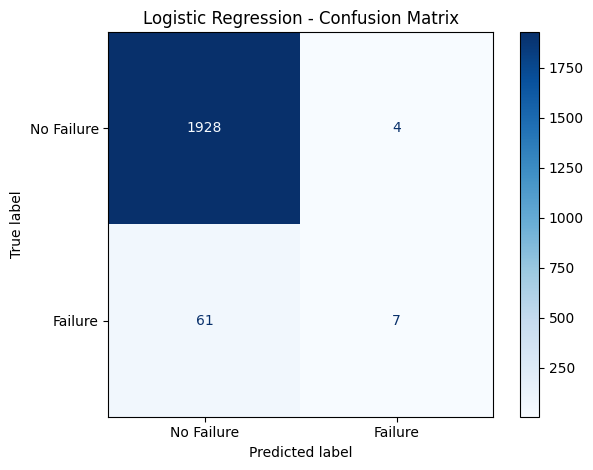

In [7]:
ax = metrics.plot.bar(x="Metric", y="Score", legend=False, figsize=(9,5), color="steelblue")
ax.set(title="Logistic Regression - Test Performance", xlabel="", ylabel="Score", ylim=(0,1))
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=["No Failure","Failure"],cmap="Blues",values_format="d")
plt.title("Logistic Regression - Confusion Matrix");plt.tight_layout()
plt.show()

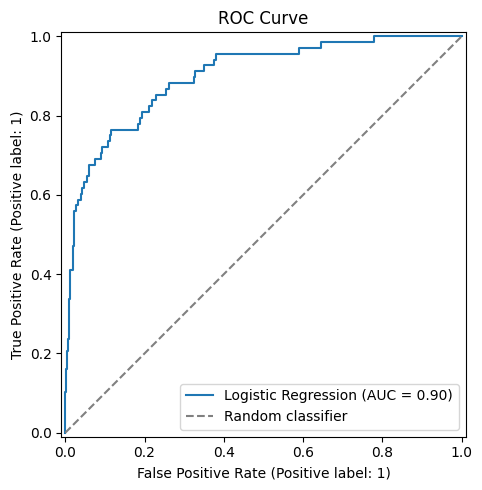

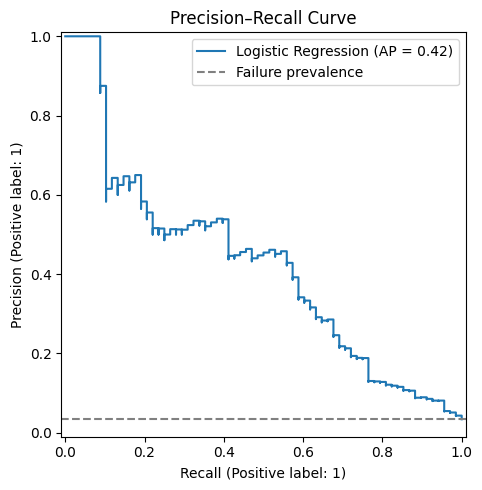

In [8]:
fig, ax = plt.subplots(figsize=(6,5))
RocCurveDisplay.from_predictions(y_test,y_prob,ax=ax,name="Logistic Regression")
ax.plot([0,1],[0,1],"--",color="gray",label="Random classifier")
ax.legend();ax.set_title("ROC Curve");plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6,5))
PrecisionRecallDisplay.from_predictions(y_test,y_prob,ax=ax,name="Logistic Regression")
ax.axhline(y_test.mean(),ls="--",color="gray",label="Failure prevalence")
ax.legend();ax.set_title("Precision–Recall Curve");plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

false_alarm_rate = fp / (fp + tn)
print(f"False Alarm Rate (FPR): {false_alarm_rate:.2%}")

False Alarm Rate (FPR): 0.21%
